# EconoCausal: Discount Effectiveness with Double Machine Learning
**Dataset:** Synthetic customer discount data (5,000 records). **Scope note:** this estimates the effect of *receiving a discount*, not the effect of continuous product price changes. Synthetic observational data do not by themselves guarantee causal identification.

## 1. Setup and load data
Upload the CSV to Colab, or place it next to this notebook. Change `CSV_PATH` if needed.

In [6]:
from google.colab import files

uploaded = files.upload()

Saving econocausal_synthetic_customers.csv to econocausal_synthetic_customers.csv


In [7]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.model_selection import StratifiedKFold
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.ensemble import RandomForestClassifier, RandomForestRegressor

# Dataset path
CSV_PATH = "econocausal_synthetic_customers.csv"

# Load dataset
df = pd.read_csv(CSV_PATH)

# Display dataset
print("Dataset Shape:", df.shape)
display(df.head())

Dataset Shape: (5000, 16)


,customer_id,age,annual_income_inr,past_purchases_12m,days_since_last_purchase,website_visits_30d,email_engagement_score,customer_segment,region,season,discount_received,discount_percent,purchased,basket_value_inr,discount_cost_inr,net_revenue_inr
0,CUST00001,22,46437,3,10,4,0.180,budget,East,regular,1,10,1,1576.55,157.66,1418.89
1,CUST00002,59,44755,4,20,5,0.328,regular,South,sale_event,0,0,1,2183.66,0.00,2183.66
2,CUST00003,52,77740,5,108,4,0.212,premium,East,festival,1,20,1,2469.38,493.88,1975.50
3,CUST00004,41,79514,5,36,5,0.383,premium,South,regular,0,0,0,0.00,0.00,0.00
4,CUST00005,40,43230,1,16,5,0.598,budget,South,regular,0,0,1,1289.21,0.00,1289.21


## 2. Data validation and EDA

In [8]:
print(df.isna().sum())
print("Duplicates:", df.duplicated().sum())
print(df.groupby("discount_received")["purchased"].agg(["count", "mean"]))
print(pd.crosstab(df["discount_received"],df["discount_percent"]))
assert df["discount_received"].isin([0,1]).all()
assert df["purchased"].isin([0,1]).all()

customer_id                 0
age                         0
annual_income_inr           0
past_purchases_12m          0
days_since_last_purchase    0
website_visits_30d          0
email_engagement_score      0
customer_segment            0
region                      0
season                      0
discount_received           0
discount_percent            0
purchased                   0
basket_value_inr            0
discount_cost_inr           0
net_revenue_inr             0
dtype: int64
Duplicates: 0
                   count      mean
discount_received                 
0                   2290  0.509170
1                   2710  0.549446
discount_percent     0    5     10   20
discount_received                      
0                  2290    0     0    0
1                     0  913  1242  555


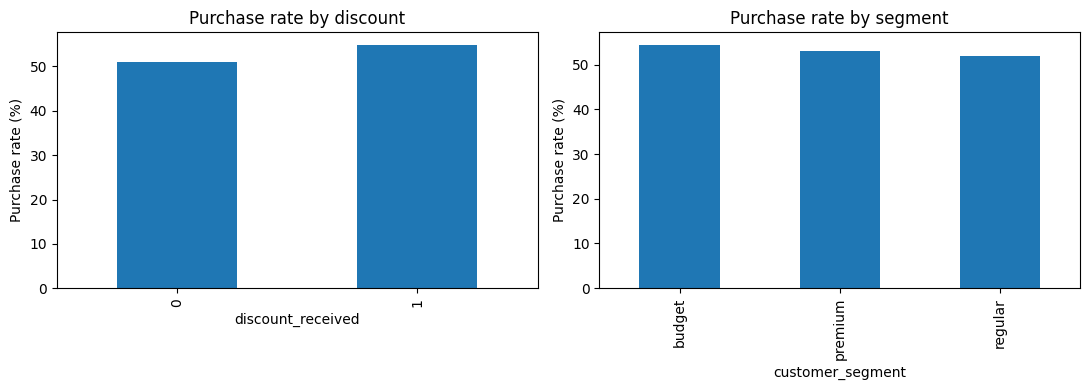

In [9]:
fig, axes = plt.subplots(1,2,figsize=(11,4))
df.groupby("discount_received")["purchased"].mean().mul(100).plot.bar(ax=axes[0],title="Purchase rate by discount",ylabel="Purchase rate (%)")
df.groupby("customer_segment")["purchased"].mean().mul(100).plot.bar(ax=axes[1],title="Purchase rate by segment",ylabel="Purchase rate (%)")
plt.tight_layout(); plt.show()

## 3. Causal question and assumptions
**Treatment:** `discount_received` (binary). **Outcome:** `purchased` (binary). **Controls:** customer information assumed measured before discount assignment. We **exclude** `discount_percent` (a treatment attribute), `basket_value_inr`, `discount_cost_inr`, and `net_revenue_inr` (post-treatment outcomes/derivatives).

Identification requires conditional exchangeability (no unmeasured confounders), positivity/overlap, consistency, and no interference. We cannot verify all assumptions from the CSV. The partially linear model also assumes a constant additive treatment effect on the probability scale.

## 4. Five-fold cross-fitted Double Machine Learning (PLR)

In [10]:
features = ["age","annual_income_inr","past_purchases_12m","days_since_last_purchase","website_visits_30d","email_engagement_score","customer_segment","region","season"]
categorical = ["customer_segment","region","season"]
numerical = [c for c in features if c not in categorical]
X=df[features]; T=df["discount_received"].to_numpy(float); Y=df["purchased"].to_numpy(float)
encoder=ColumnTransformer([("num","passthrough",numerical),("cat",OneHotEncoder(handle_unknown="ignore"),categorical)])
folds=StratifiedKFold(n_splits=5,shuffle=True,random_state=42)
m=np.zeros(len(df));g=np.zeros(len(df))
for train,test in folds.split(X,T):
    xtr=encoder.fit_transform(X.iloc[train]); xte=encoder.transform(X.iloc[test])
    prop=RandomForestClassifier(n_estimators=120,min_samples_leaf=20,max_features=.8,n_jobs=-1,random_state=42)
    outcome=RandomForestRegressor(n_estimators=120,min_samples_leaf=20,max_features=.8,n_jobs=-1,random_state=42)
    prop.fit(xtr,T[train]); outcome.fit(xtr,Y[train])
    m[test]=prop.predict_proba(xte)[:,1]; g[test]=outcome.predict(xte)
t_res=T-m; y_res=Y-g
theta=np.sum(t_res*y_res)/np.sum(t_res**2)
psi=t_res*(y_res-theta*t_res)/np.mean(t_res**2)
se=np.std(psi,ddof=1)/np.sqrt(len(df))
print(f"DML effect: {theta*100:.2f} percentage points")
print(f"Approximate 95% CI: [{(theta-1.96*se)*100:.2f}, {(theta+1.96*se)*100:.2f}] pp")
print("Propensity range:",m.min(),m.max())

DML effect: 5.33 percentage points
Approximate 95% CI: [2.58, 8.07] pp
Propensity range: 0.14979335149642056 0.8647035293607866


## 5. Robustness: cross-fitted AIPW
AIPW estimates the average effect using propensity and treatment-specific outcome models. Agreement is reassuring but does not prove identification.

In [11]:
mu0=np.zeros(len(df));mu1=np.zeros(len(df));p=np.zeros(len(df))
for train,test in folds.split(X,T):
    xtr=encoder.fit_transform(X.iloc[train]);xte=encoder.transform(X.iloc[test])
    prop=RandomForestClassifier(n_estimators=120,min_samples_leaf=20,n_jobs=-1,random_state=7)
    prop.fit(xtr,T[train]);p[test]=prop.predict_proba(xte)[:,1]
    for value,target in [(0,mu0),(1,mu1)]:
        mdl=RandomForestRegressor(n_estimators=120,min_samples_leaf=20,n_jobs=-1,random_state=7)
        mask=T[train]==value
        mdl.fit(xtr[mask],Y[train][mask]);target[test]=mdl.predict(xte)
pclip=np.clip(p,.05,.95)
aipw_scores=mu1-mu0+T*(Y-mu1)/pclip-(1-T)*(Y-mu0)/(1-pclip)
ate=aipw_scores.mean();ate_se=aipw_scores.std(ddof=1)/np.sqrt(len(df))
print(f"AIPW effect: {ate*100:.2f} pp; 95% CI [{(ate-1.96*ate_se)*100:.2f}, {(ate+1.96*ate_se)*100:.2f}] pp")

AIPW effect: 5.70 pp; 95% CI [2.93, 8.47] pp


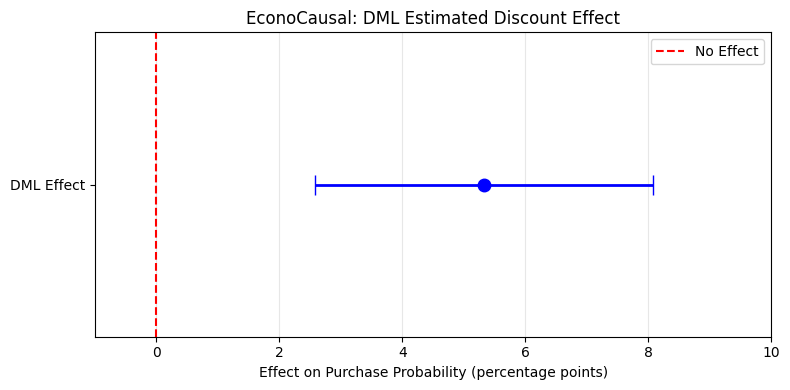

In [1]:
import matplotlib.pyplot as plt

# Your previously calculated DML results
effect_pp = 5.33
lower_pp = 2.58
upper_pp = 8.07

# Calculate confidence interval error bars
lower_error = effect_pp - lower_pp
upper_error = upper_pp - effect_pp

plt.figure(figsize=(8, 4))

plt.errorbar(
    effect_pp,
    0,
    xerr=[[lower_error], [upper_error]],
    fmt="o",
    color="blue",
    capsize=7,
    markersize=9,
    linewidth=2
)

plt.axvline(
    0,
    color="red",
    linestyle="--",
    label="No Effect"
)

plt.yticks([0], ["DML Effect"])

plt.xlabel("Effect on Purchase Probability (percentage points)")
plt.title("EconoCausal: DML Estimated Discount Effect")

plt.xlim(-1, 10)
plt.grid(axis="x", alpha=0.3)
plt.legend()

plt.tight_layout()
plt.savefig("dml_effect.png", dpi=300)
plt.show()

## 6. Interpretation and limitations
These are **assumption-dependent** causal estimates for discount assignment. This dataset is synthetic, and the assignment mechanism is unknown. We cannot claim that the reported effects are experimentally verified. The data contain no product prices, so **optimal dynamic prices cannot be calculated**. A separate randomized price experiment or longitudinal pricing dataset is needed for that goal.

In [12]:
pd.DataFrame({"Method":["Raw difference","DML PLR","AIPW"],"Effect (pp)":[100*(df.loc[df.discount_received==1,"purchased"].mean()-df.loc[df.discount_received==0,"purchased"].mean()),theta*100,ate*100]}).round(2)

,Method,Effect (pp)
0,Raw difference,4.03
1,DML PLR,5.33
2,AIPW,5.70


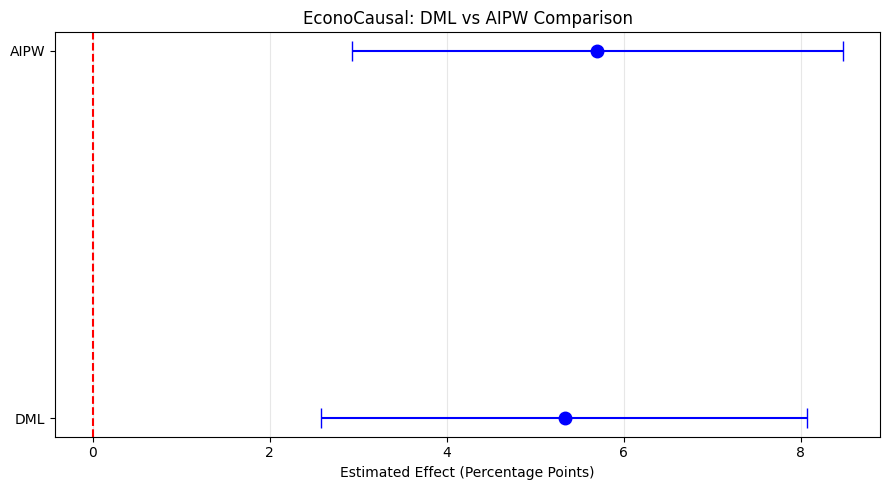

In [2]:
import numpy as np
import matplotlib.pyplot as plt

methods = ["DML", "AIPW"]

effects = np.array([5.33, 5.70])
lower = np.array([2.58, 2.93])
upper = np.array([8.07, 8.47])

errors = np.array([
    effects - lower,
    upper - effects
])

plt.figure(figsize=(9, 5))

plt.errorbar(
    effects,
    methods,
    xerr=errors,
    fmt="o",
    color="blue",
    capsize=7,
    markersize=9
)

plt.axvline(0, color="red", linestyle="--")

plt.xlabel("Estimated Effect (Percentage Points)")
plt.title("EconoCausal: DML vs AIPW Comparison")
plt.grid(axis="x", alpha=0.3)

plt.tight_layout()
plt.savefig("dml_vs_aipw.png", dpi=300)
plt.show()